# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [51]:
df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,GBD,GBA,BSH,BSD,BSA,home_team_outcome,away_team_outcome,B365H_log,country_label,league_bin
0,145,1,1,2008/2009,24,2009-02-28 00:00:00,493016,9996,8635,1,...,3.60,1.60,5.50,3.60,1.53,Other Outcome,Other Outcome,1.909543,1,League_Bin_1
1,146,1,1,2008/2009,24,2009-02-27 00:00:00,493017,8203,9987,2,...,3.25,2.30,2.80,3.20,2.25,Home Win,Other Outcome,1.386294,1,League_Bin_1
2,147,1,1,2008/2009,24,2009-02-28 00:00:00,493018,9986,9998,3,...,3.25,4.25,1.91,3.25,3.60,Home Win,Other Outcome,1.098612,1,League_Bin_1
3,148,1,1,2008/2009,24,2009-03-01 00:00:00,493019,9985,9984,4,...,3.75,7.50,1.40,3.75,7.50,Home Win,Other Outcome,0.891998,1,League_Bin_1
4,149,1,1,2008/2009,24,2009-03-01 00:00:00,493020,9994,9991,0,...,3.20,2.50,2.62,3.20,2.38,Other Outcome,Away Win,1.286474,1,League_Bin_1


## Carregando o Dataset

In [52]:
import kagglehub
import os
import pandas as pd
import sqlite3

# Download latest version
path = kagglehub.dataset_download("hugomathien/soccer")

print("Path to dataset files:", path)
print("Contents of the downloaded directory:", os.listdir(path))

# Connect to the SQLite database
conn = sqlite3.connect(os.path.join(path, 'database.sqlite'))

df = pd.read_sql_query("SELECT * FROM Match", conn)
conn.close()

Using Colab cache for faster access to the 'soccer' dataset.
Path to dataset files: /kaggle/input/soccer
Contents of the downloaded directory: ['database.sqlite']


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

escolhi um database do futebol europeu, muito focado na premier league, apostas e correlação dessas estatisticas com o desempenho das equipes vencedoras

### Dimensão e Tipos de Dados

In [53]:
df.shape

(25979, 115)

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Columns: 115 entries, id to BSA
dtypes: float64(96), int64(9), object(10)
memory usage: 22.8+ MB


In [55]:
df.describe()

,id,country_id,league_id,stage,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,home_player_X1,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
count,25979.000000,25979.000000,25979.000000,25979.000000,2.597900e+04,25979.000000,25979.000000,25979.000000,25979.000000,24158.000000,...,17097.000000,22568.000000,22568.000000,22568.000000,14162.000000,14162.000000,14162.000000,14161.000000,14161.000000,14161.000000
mean,12990.000000,11738.630317,11738.630317,18.242773,1.195429e+06,9984.371993,9984.475115,1.544594,1.160938,0.999586,...,4.622343,2.668107,3.899048,4.840281,2.498764,3.648189,4.353097,2.497894,3.660742,4.405663
std,7499.635658,7553.936759,7553.936759,10.407354,4.946279e+05,14087.453758,14087.445135,1.297158,1.142110,0.022284,...,3.632164,1.928753,1.248221,4.318338,1.489299,0.867440,3.010189,1.507793,0.868272,3.189814
min,1.000000,1.000000,1.000000,1.000000,4.831290e+05,1601.000000,1601.000000,0.000000,0.000000,0.000000,...,1.100000,1.030000,1.620000,1.080000,1.050000,1.450000,1.120000,1.040000,1.330000,1.120000
25%,6495.500000,4769.000000,4769.000000,9.000000,7.684365e+05,8475.000000,8475.000000,1.000000,0.000000,1.000000,...,2.500000,1.700000,3.300000,2.550000,1.670000,3.200000,2.500000,1.670000,3.250000,2.500000
50%,12990.000000,10257.000000,10257.000000,18.000000,1.147511e+06,8697.000000,8697.000000,1.000000,1.000000,1.000000,...,3.500000,2.150000,3.500000,3.500000,2.100000,3.300000,3.400000,2.100000,3.400000,3.400000
75%,19484.500000,17642.000000,17642.000000,27.000000,1.709852e+06,9925.000000,9925.000000,2.000000,2.000000,1.000000,...,5.250000,2.800000,4.000000,5.400000,2.650000,3.750000,5.000000,2.620000,3.750000,5.000000
max,25979.000000,24558.000000,24558.000000,38.000000,2.216672e+06,274581.000000,274581.000000,10.000000,9.000000,2.000000,...,41.000000,36.000000,26.000000,67.000000,21.000000,11.000000,34.000000,17.000000,13.000000,34.000000


podemos ver aqui uma quantidade massiva de dados, mostrando que potencialmente a volatilidade deles é bem alta

### Duplicadas

In [59]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [60]:
import numpy as np
# Create a target variable for soccer: 'Home Win' vs 'Other Outcome'
# 'Home Win' if home_team_goal > away_team_goal, 'Other Outcome' otherwise (Draw or Away Win)
df["home_team_outcome"] = np.where(df["home_team_goal"] > df["away_team_goal"], "Home Win", "Other Outcome")

# Display counts of the new target variable
print(df["home_team_outcome"].value_counts())

# The original 'num' column from the Heart Disease dataset does not exist in this dataset,
# so the line trying to drop it is removed to prevent an error.
# df.drop(columns=["num"], inplace=True)

df.head()

home_team_outcome
Other Outcome    14062
Home Win         11917
Name: count, dtype: int64


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA,home_team_outcome,away_team_outcome
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20,Other Outcome,Other Outcome
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60,Other Outcome,Other Outcome
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75,Other Outcome,Away Win
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50,Home Win,Other Outcome
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67,Other Outcome,Away Win


In [61]:
import numpy as np
# Create a target variable for soccer: 'Away Win' vs 'Other Outcome'
# 'Away Win' if away_team_goal > home_team_goal, 'Other Outcome' otherwise (Draw or Home Win)
df["away_team_outcome"] = np.where(df["away_team_goal"] > df["home_team_goal"], "Away Win", "Other Outcome")

# Display counts of the new target variable
print(df["away_team_outcome"].value_counts())

df.head()

away_team_outcome
Other Outcome    18513
Away Win          7466
Name: count, dtype: int64


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA,home_team_outcome,away_team_outcome
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20,Other Outcome,Other Outcome
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60,Other Outcome,Other Outcome
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75,Other Outcome,Away Win
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50,Home Win,Other Outcome
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67,Other Outcome,Away Win


## 2. Dados Faltantes

In [62]:
df.isna().sum()

,0
id,0
country_id,0
league_id,0
season,0
stage,0
...,...
BSH,11818
BSD,11818
BSA,11818
home_team_outcome,0


os dados faltantes se dão pois nem tudo acontece na partida, nada é estatisticamente necessário e fatidico além de que se um ganha outro perde e se nenhum ganha é empate

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos 3 features relacionadas a bets que, como explicado acima, são antagonicas e nao podem acontecer em paralelo

Pela fonte de dados observamos que:

temos as vitorias, empates e derrotas pela b356


*Como os dados foram coletados:*
- conjuntos de dados captaddos pelo historico do futebol europeu no kaggle

*Qual a natureza da fonte de dados:*
- equipes, jogos de campeonatos nacionais e jogadores.


**As ausencias ocorrem juntas?**

não mas a existencia de um significa auxencia deoutro, a exemplo de que 2 times nao levam o status de vitoria ou que ganharam em casa na mesma partida




In [63]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['home_player_X1', 'home_player_X2', 'home_player_X3', 'home_player_X4', 'home_player_X5', 'home_player_X6', 'home_player_X7', 'home_player_X8', 'home_player_X9', 'home_player_X10', 'home_player_X11', 'away_player_X1', 'away_player_X2', 'away_player_X3', 'away_player_X4', 'away_player_X5', 'away_player_X6', 'away_player_X7', 'away_player_X8', 'away_player_X9', 'away_player_X10', 'away_player_X11', 'home_player_Y1', 'home_player_Y2', 'home_player_Y3', 'home_player_Y4', 'home_player_Y5', 'home_player_Y6', 'home_player_Y7', 'home_player_Y8', 'home_player_Y9', 'home_player_Y10', 'home_player_Y11', 'away_player_Y1', 'away_player_Y2', 'away_player_Y3', 'away_player_Y4', 'away_player_Y5', 'away_player_Y6', 'away_player_Y7', 'away_player_Y8', 'away_player_Y9', 'away_player_Y10', 'away_player_Y11', 'home_player_1', 'home_player_2', 'home_player_3', 'home_player_4', 'home_player_5', 'home_player_6', 'home_player_7', 'home_player_8', 'home_player_9', 'home_player_10', 'home_

aqui temos muitas auxências porém esperadas e controladas


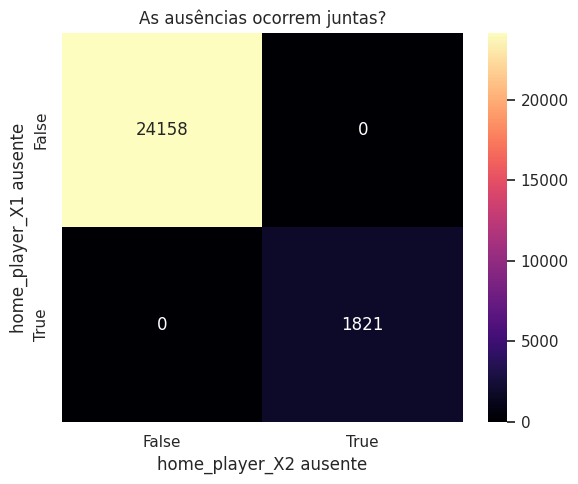

In [64]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [65]:
VARS_QUANT = ["home_team_goal", "away_team_goal", "B365H", "B365D", "B365A"]
VARS_QUALI = ["season", "country_id", "league_id"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
home_team_goal,1.54,1.00,1.30,0.00,10.00,0.93,1.08
away_team_goal,1.16,1.00,1.14,0.00,9.00,1.10,1.46
B365H,2.63,2.10,1.79,1.04,26.00,3.54,18.44
B365D,3.84,3.50,1.12,1.40,17.00,3.73,21.42
B365A,4.66,3.50,3.73,1.08,51.00,2.92,12.51


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

a assimetria é altissima pois os dados além de não serem lineares veriam bruscamente de acordo com o jogo e situação, são extremamente volateis

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?


no caso dos meus dados sobre futebol, sim, pois nem sempre o obvio ou o esperado acontece com precisão


### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


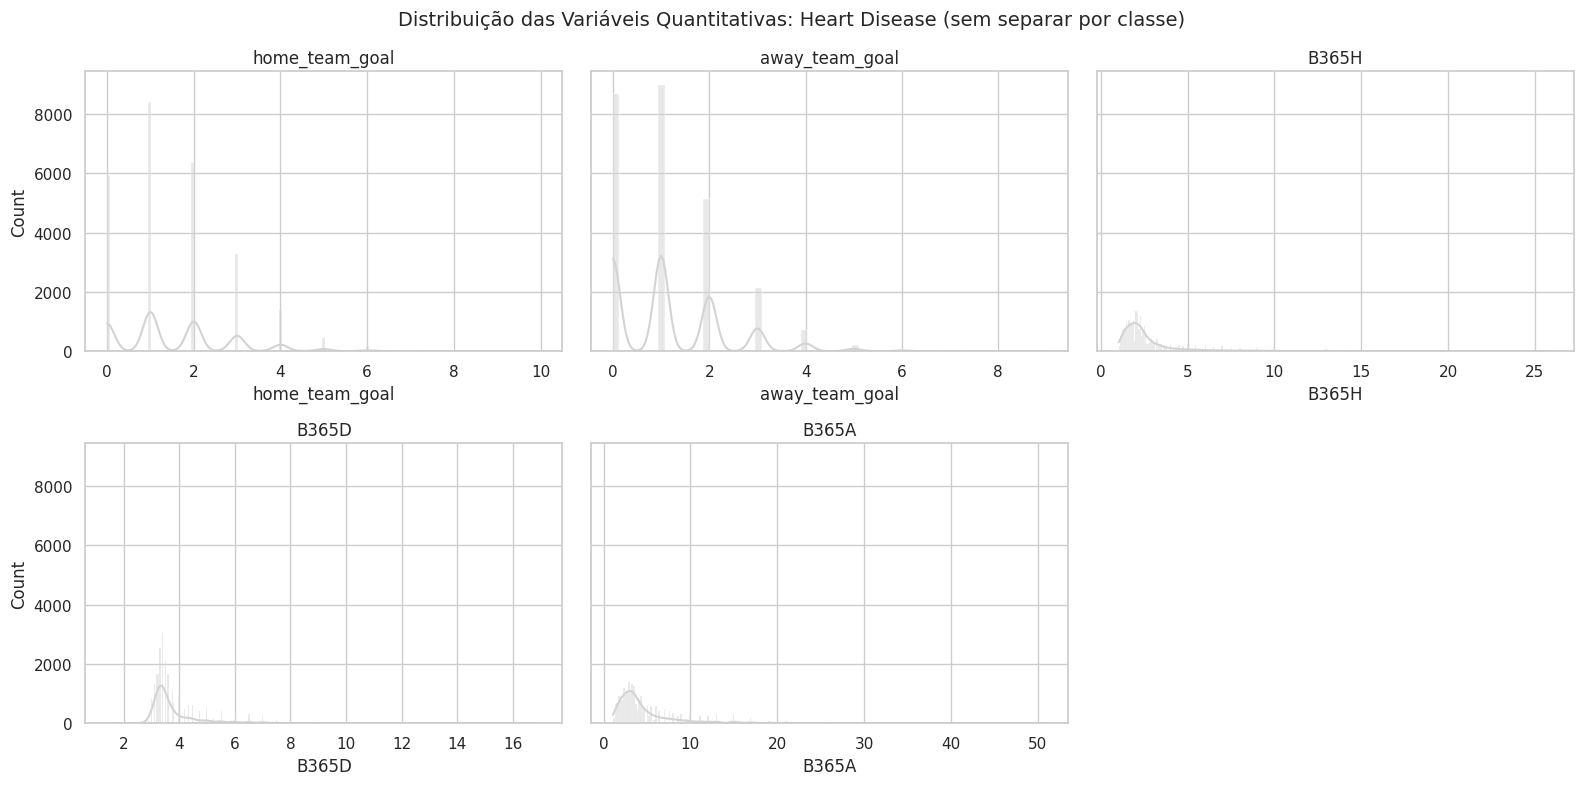

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Heart Disease (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

a distribuição é curta horizontalmente ms extensa verticalmente pois os valores menores se tratando de gols por exemplo ocorrem em quande quantidade e as goleadas são muito mais raras e nem sempre vao representar bem o que buscamos quando falamos de odds por exemplo, a partir disso carregariamos o fator "sorte"

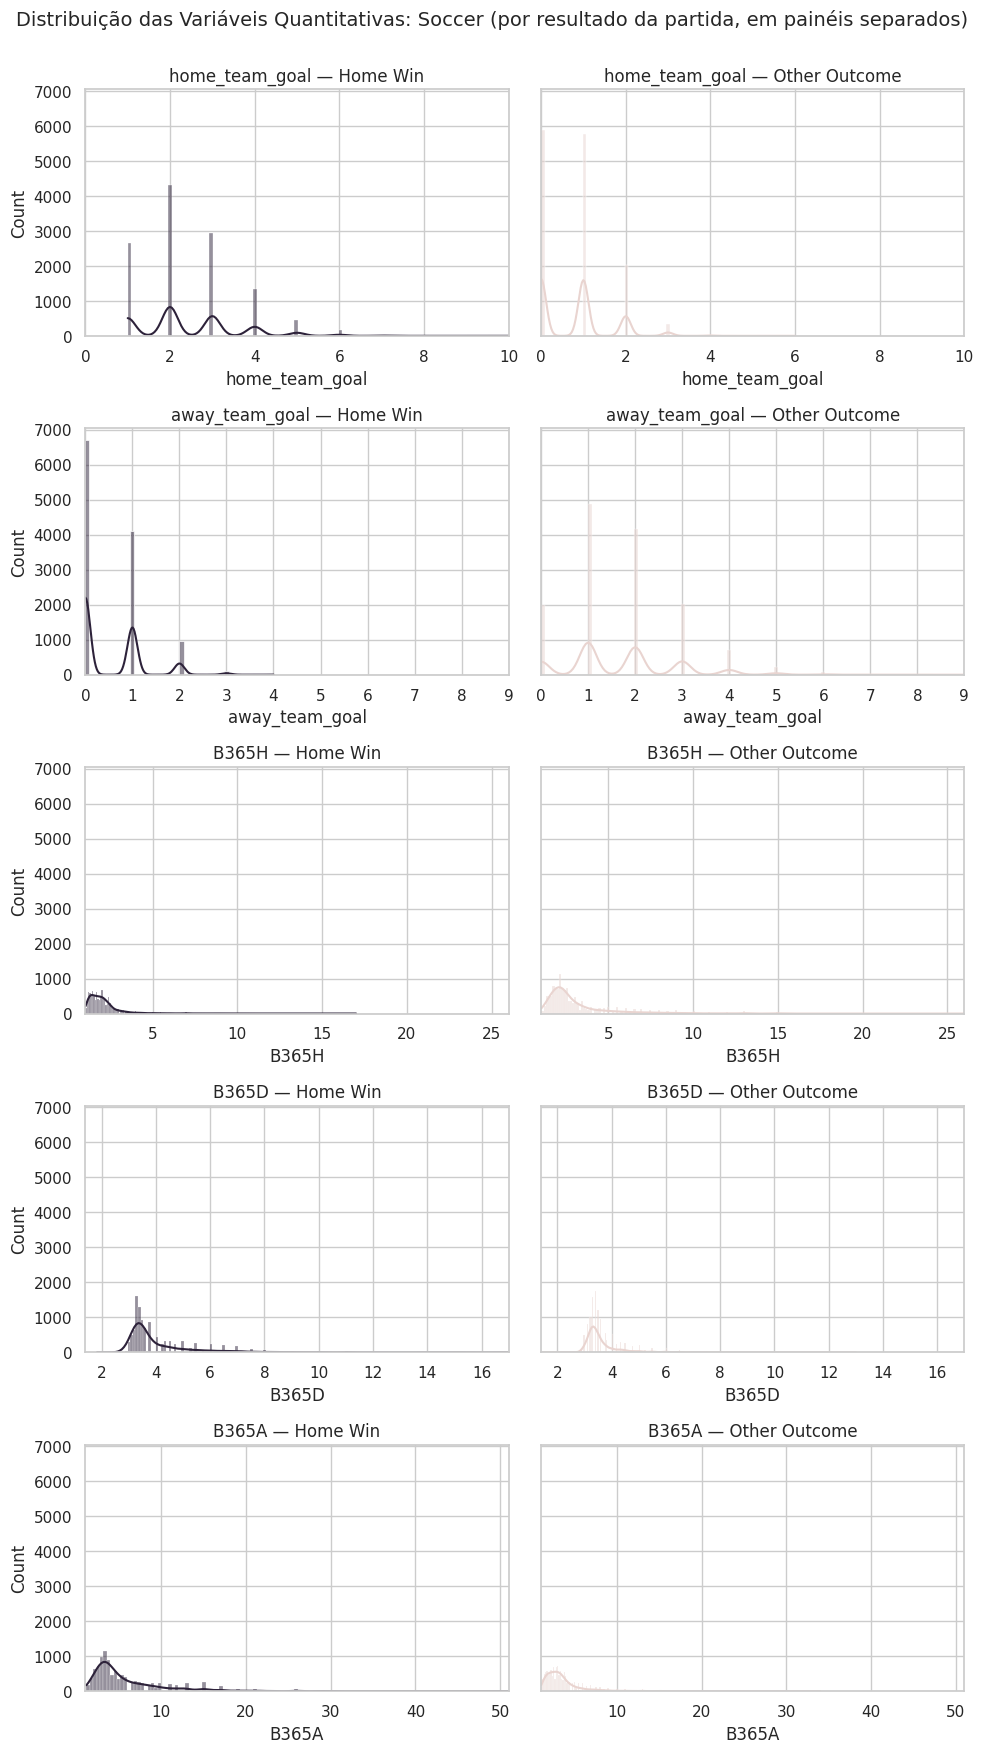

In [70]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    # Calculate limits from the entire column, dropping NaNs if any, to ensure consistent axes across subplots
    # Use a default range if the column is entirely NaN or has issues with min/max
    col_data = df[col].dropna()
    lim_min = col_data.min() if not col_data.empty else 0
    lim_max = col_data.max() if not col_data.empty else 10 # Default to 10 or another sensible max if no data
    lim = (lim_min, lim_max)

    # The classes are now "Home Win" and "Other Outcome" based on the new target variable
    for j, (classe, cor) in enumerate([("Home Win", COR_DESTAQUE), ("Other Outcome", COR_CONTEXTO)]):
        subset = df[df["home_team_outcome"] == classe]
        if not subset.empty: # Only plot if the subset is not empty to avoid errors
            sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Soccer (por resultado da partida, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?


pode´se ver que ainda temos resultados largos mas concentrados em alta massividade nos valores menores, como o esperado


#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25979.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — home_team_goal: estatística=0.8868, p-valor=2.61e-85
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


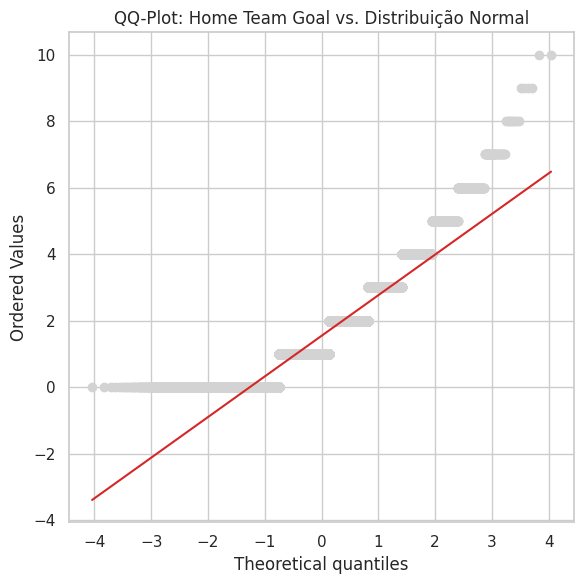

In [71]:
stat_sw, p_valor_sw = stats.shapiro(df["home_team_goal"].dropna())
print(f"Shapiro-Wilk — home_team_goal: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — home_team_goal"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["home_team_goal"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Home Team Goal vs. Distribuição Normal")
plt.tight_layout()
plt.show()

#### Análise de Cartões

#### Análise de Odds

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 22592.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — B365H: estatística=0.6501, p-valor=5.412e-110
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


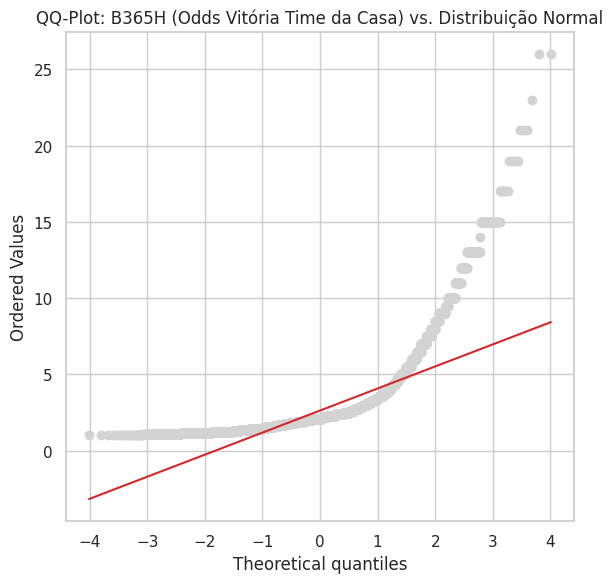

In [76]:
# Shapiro-Wilk test for 'B365H'
# Dropping NaNs as the test requires complete observations
stat_sw_b365h, p_valor_sw_b365h = stats.shapiro(df["B365H"].dropna())
print(f"Shapiro-Wilk — B365H: estatística={stat_sw_b365h:.4f}, p-valor={p_valor_sw_b365h:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw_b365h < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — B365H"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["B365H"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: B365H (Odds Vitória Time da Casa) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

nos dois acima podemos ver que o numero negativo nao corresponde bem ao que é apresentado porém que obviamente a partir do momento que observamos a as vitorias do time da casa, temos crescimentos de linhas continuas devido a que gols e as proprias vitorias, exceto as odds, são numeros necessáriamente exatos

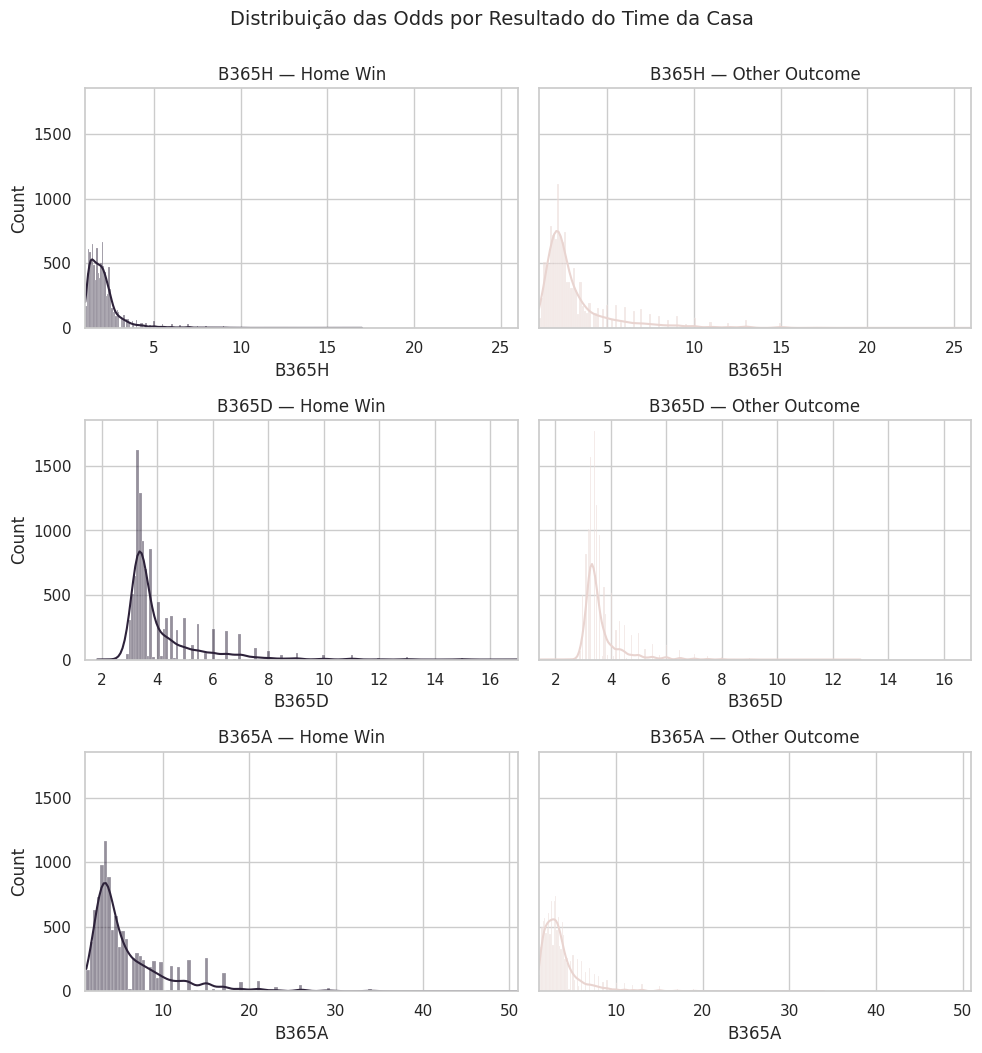

In [77]:
odds_cols = ["B365H", "B365D", "B365A"]

fig, axes = plt.subplots(len(odds_cols), 2, figsize=(10, 3.5 * len(odds_cols)), sharey=True)

for i, col in enumerate(odds_cols):
    # Calculate limits from the entire column, dropping NaNs if any, to ensure consistent axes across subplots
    col_data = df[col].dropna()
    lim_min = col_data.min() if not col_data.empty else 0
    lim_max = col_data.max() if not col_data.empty else 10
    lim = (lim_min, lim_max)

    # Use 'home_team_outcome' for grouping
    for j, (classe, cor) in enumerate([("Home Win", COR_DESTAQUE), ("Other Outcome", COR_CONTEXTO)]):
        subset = df[df["home_team_outcome"] == classe]
        if not subset.empty:
            if col in subset.columns and not subset[col].dropna().empty:
                sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
            else:
                axes[i, j].text(0.5, 0.5, f"No '{col}' data for this class", horizontalalignment='center', verticalalignment='center', transform=axes[i, j].transAxes)
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Odds por Resultado do Time da Casa", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

aqui, geralmente as odds de vitória que passam a normalidade seguem vitorias improvaveis ou derrotas improvaveis que "pagaram" maias do que o esperado. " obs engraçada: se tivessimos o numero de vencedores das apostas poderiamos tirar o prejuízo das casas de apostas pelos outliers

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [78]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25979.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 22592.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
home_team_goal,0.8868,0.0,True
away_team_goal,0.8449,0.0,True
B365H,0.6501,0.0,True
B365D,0.6246,0.0,True
B365A,0.7083,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

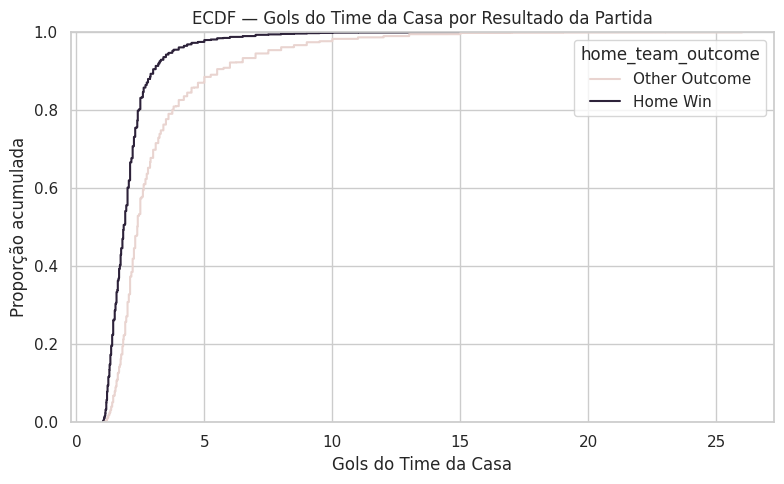

In [79]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="B365H", hue="home_team_outcome",
             palette={"Other Outcome": COR_CONTEXTO, "Home Win": COR_DESTAQUE})
plt.title("ECDF — Gols do Time da Casa por Resultado da Partida")
plt.xlabel("Gols do Time da Casa")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

Para interpretar futebolisticamente:

*   **Eixo X (`B365H`):** Representa as odds oferecidas pelas casas de apostas para o time da casa vencer. Odds mais baixas (à esquerda) indicam que o time da casa era mais favorito; odds mais altas (à direita) indicam que era menos favorito.

*   **Eixo Y (Proporção acumulada):** Mostra a porcentagem de jogos em cada grupo (Vitória em Casa ou Outro Resultado) em que as odds `B365H` foram menores ou iguais ao valor correspondente no eixo X.

*   **Curva 'Home Win' (Vitória em Casa, roxo escuro):** Esta curva tende a subir mais rápido e a ficar mais à esquerda. Isso significa que a maioria das vitórias em casa ocorreu quando as odds para o time da casa vencer eram mais baixas (ou seja, quando o time era mais favorito).

*   **Curva 'Other Outcome' (Outro Resultado, rosa claro):** Esta curva sobe mais lentamente e fica mais à direita. Isso indica que, nos jogos em que o time da casa não venceu (empate ou derrota), as odds para sua vitória (`B365H`) eram geralmente mais altas (ou seja, o time era menos favorito ou um azarão).

**Em resumo:** Onde as duas curvas estão mais distantes verticalmente, é onde a diferença na distribuição das odds entre uma 'Vitória em Casa' e um 'Outro Resultado' é mais notável. O gráfico confirma a expectativa de que times com odds mais baixas (mais favoritos) têm maior probabilidade de vencer em casa.

### Métricas de Tendêncial Central

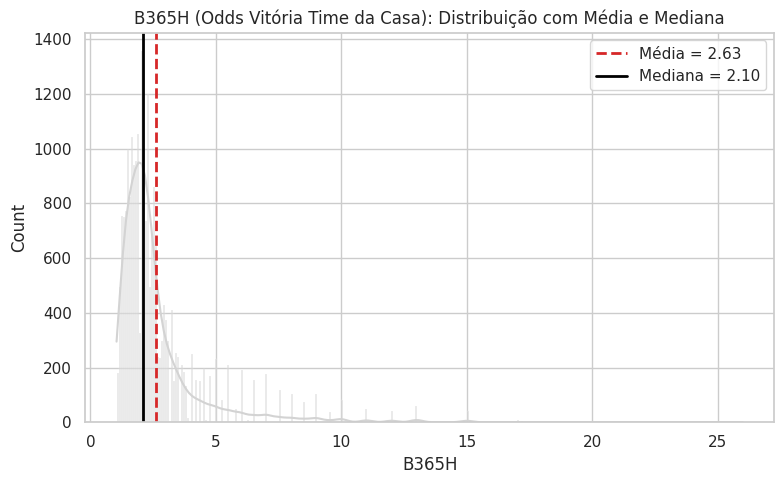

In [80]:
media_b365h = df["B365H"].mean()
mediana_b365h = df["B365H"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="B365H", kde=True, color=COR_NEUTRA)
plt.axvline(media_b365h, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_b365h:.2f}")
plt.axvline(mediana_b365h, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_b365h:.2f}")
plt.title("B365H (Odds Vitória Time da Casa): Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

aqui segue a logica da media das odds que são vencidas pelo time da casa

### Dispersão

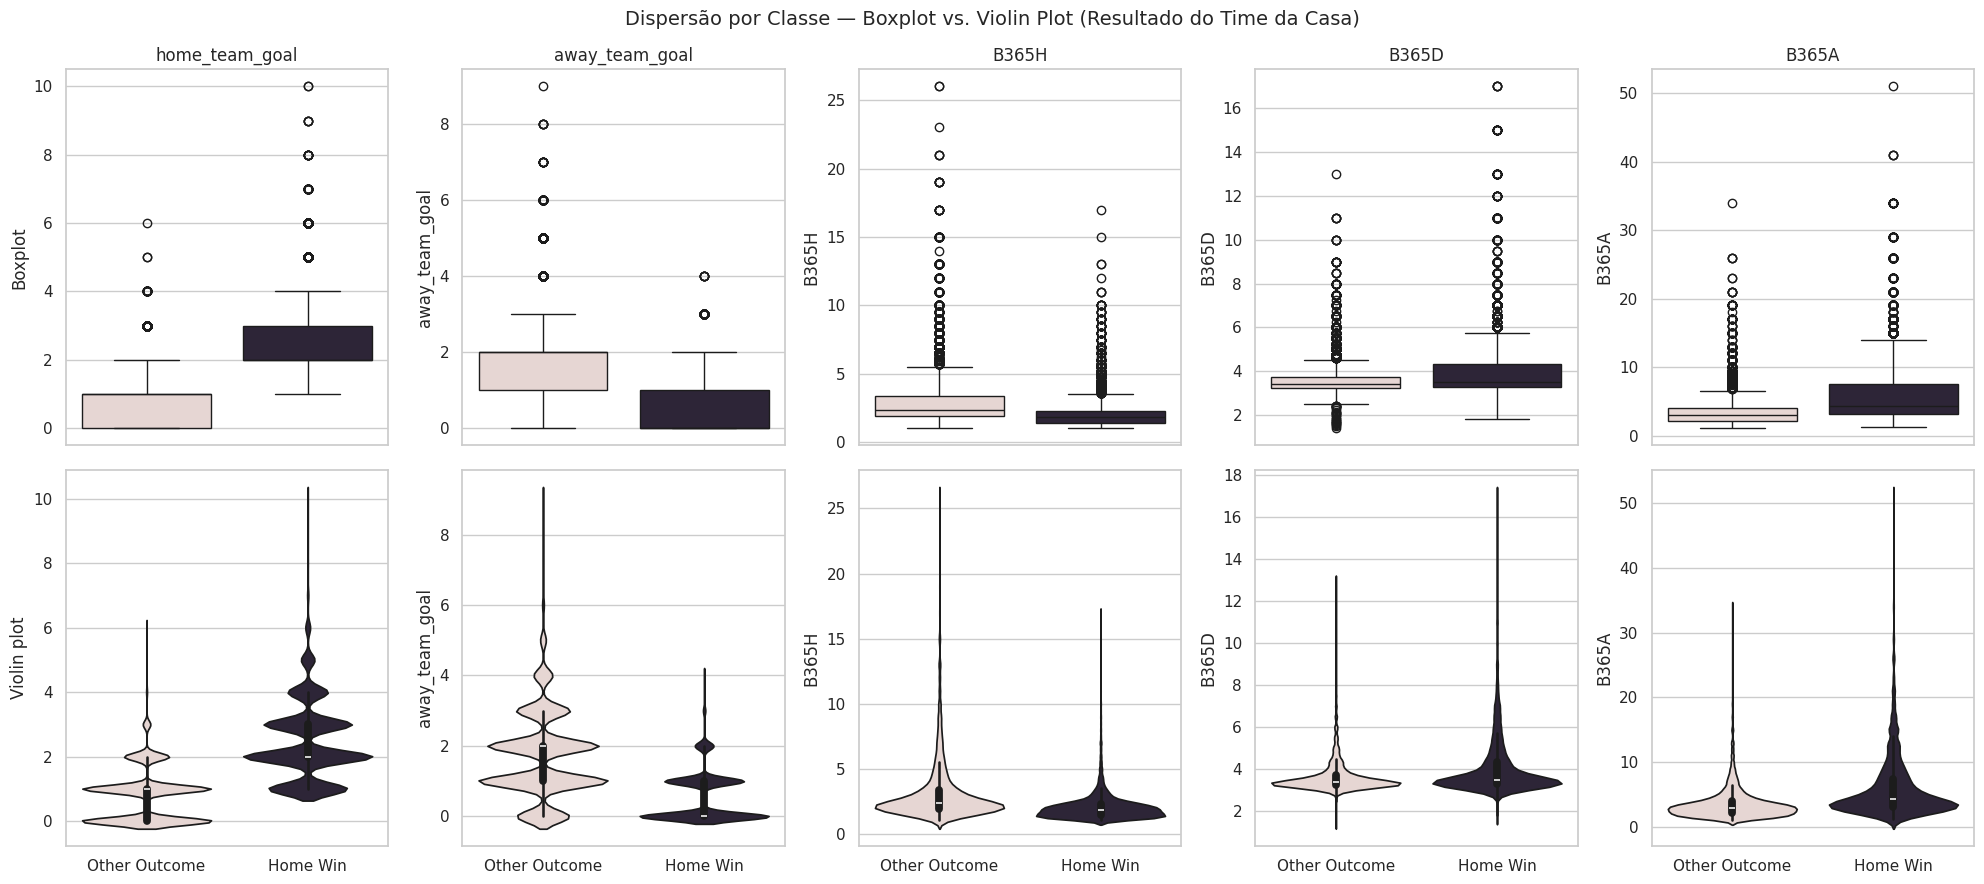

In [82]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Other Outcome": COR_CONTEXTO, "Home Win": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="home_team_outcome", y=col, hue="home_team_outcome",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="home_team_outcome", y=col, hue="home_team_outcome",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot (Resultado do Time da Casa)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [28]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "percent_outliers": round((n_outliers / len(df)) * 100, 2)
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,percent_outliers
home_team_goal,-0.50,3.50,2056.0,7.91
away_team_goal,-3.00,5.00,79.0,0.30
B365H,-0.02,4.49,2210.0,8.51
B365D,2.25,5.05,2046.0,7.88
B365A,-1.62,9.38,2032.0,7.82


### Visualizando os Outliers

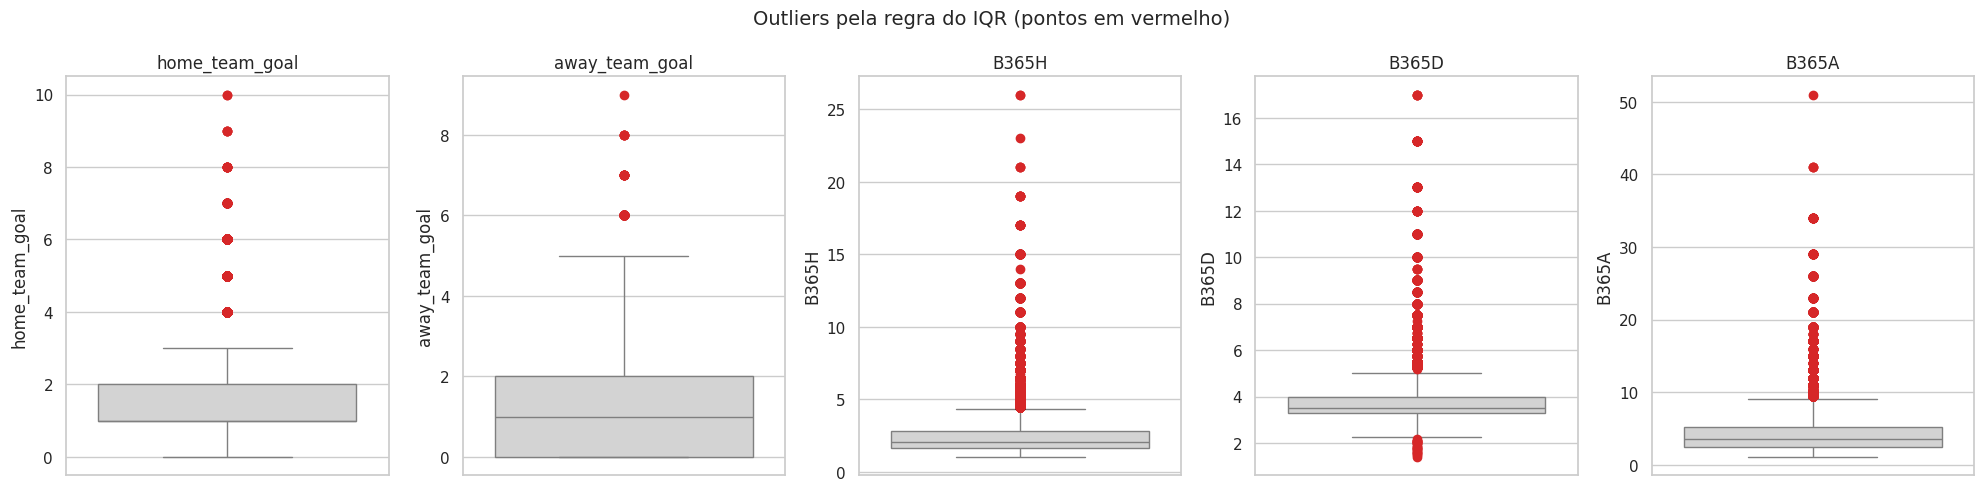

In [29]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

como ja disse antes, muitas goleadas acontecem e só de acontecerem geram goleadas e sobre as odd os outliers acontecem quando temos a famosa zebra com a vitoria menos esperada ou derrota, acontecendo, NAO APOSTEM


**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [83]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=["home_player_X1", "home_player_Y1"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 25979 | Linhas depois: 24158 | Removidas: 1821


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

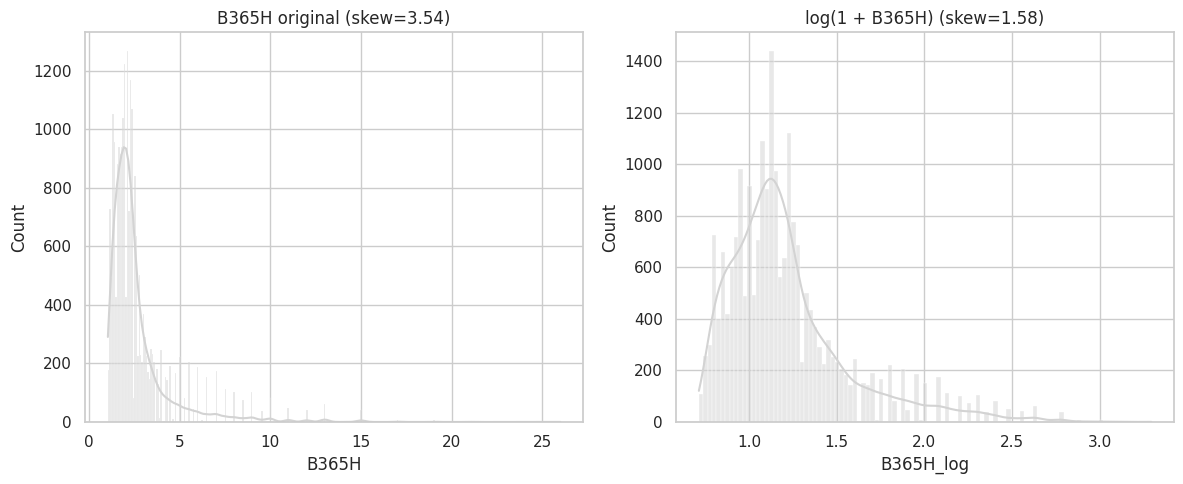

In [84]:
df["B365H_log"] = np.log1p(df["B365H"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="B365H", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"B365H original (skew={df['B365H'].skew():.2f})")

sns.histplot(data=df, x="B365H_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + B365H) (skew={df['B365H_log'].skew():.2f})")

plt.tight_layout()
plt.show()

no meu caso a assimetria fica mais controlada mas é impossivel a exclusao e redução dela em larga escala pq ao mesmo tempo que os dados sao muito volateis eles são exatos e muito precisos


**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [85]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
home_team_goal,1.55,1.00,1.30,0.00,10.00,0.93,1.10
away_team_goal,1.17,1.00,1.15,0.00,9.00,1.09,1.44
B365H,2.63,2.10,1.80,1.04,26.00,3.54,18.38
B365D,3.84,3.50,1.12,1.40,17.00,3.73,21.32
B365A,4.67,3.50,3.74,1.08,51.00,2.93,12.56


### Comparando "antes"x "depois""



In [86]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
home_team_goal,0.930,0.932,1.081,1.096,0.003,0.015
away_team_goal,1.100,1.095,1.460,1.443,-0.005,-0.017
B365H,3.541,3.542,18.438,18.380,0.001,-0.059
B365D,3.733,3.731,21.423,21.324,-0.002,-0.100
B365A,2.923,2.934,12.511,12.564,0.011,0.053


é observado que devido a essa precisão não modular dos dados, kurtosis nao teve mudança significativa em relação aos outros, como falei a concentração e variação dos dados são muito bem definidas, talvez uma metrica vendo o impacto desses resultados fosse mais precisa que só a metrica aplicada atual


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [87]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["B365H"].dropna())
print(f"Shapiro-Wilk (antes)  — B365H: estatística={stat_sw_b365h:.4f}, p-valor={p_valor_sw_b365h:.4g}")
print(f"Shapiro-Wilk (depois) — B365H: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — B365H: estatística=0.6501, p-valor=5.412e-110
Shapiro-Wilk (depois) — B365H: estatística=0.6489, p-valor=1.759e-109


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 22077.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

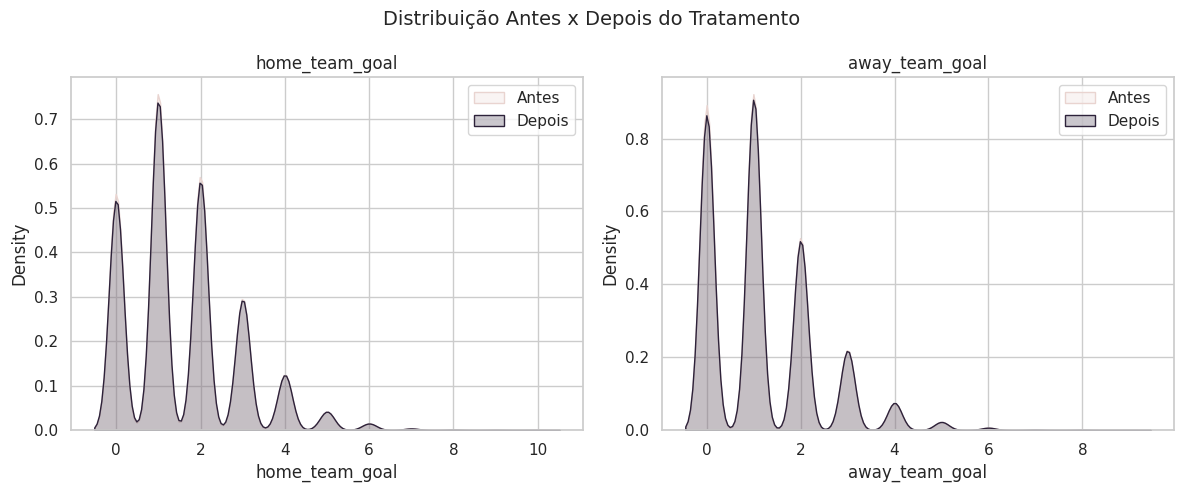

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["home_team_goal", "away_team_goal"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

como disse antes, são dados muito fechados


**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [88]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- season ---
           absoluta  relativa
season                       
2015/2016      3326     0.138
2014/2015      3325     0.138
2013/2014      3032     0.126
2010/2011      3020     0.125
2012/2013      3020     0.125
2009/2010      2990     0.124
2011/2012      2980     0.123
2008/2009      2465     0.102
\n--- country_id ---
            absoluta  relativa
country_id                    
1729            3040     0.126
4769            3040     0.126
21518           3040     0.126
10257           3017     0.125
7809            2448     0.101
13274           2243     0.093
17642           1948     0.081
19694           1824     0.076
1               1520     0.063
24558           1318     0.055
15722            720     0.030
\n--- league_id ---
           absoluta  relativa
league_id                    
1729           3040     0.126
4769           3040     0.126
21518          3040     0.126
10257          3017     0.125
7809           2448     0.101
13274          2243     0.093

#### Visualizando as frequências

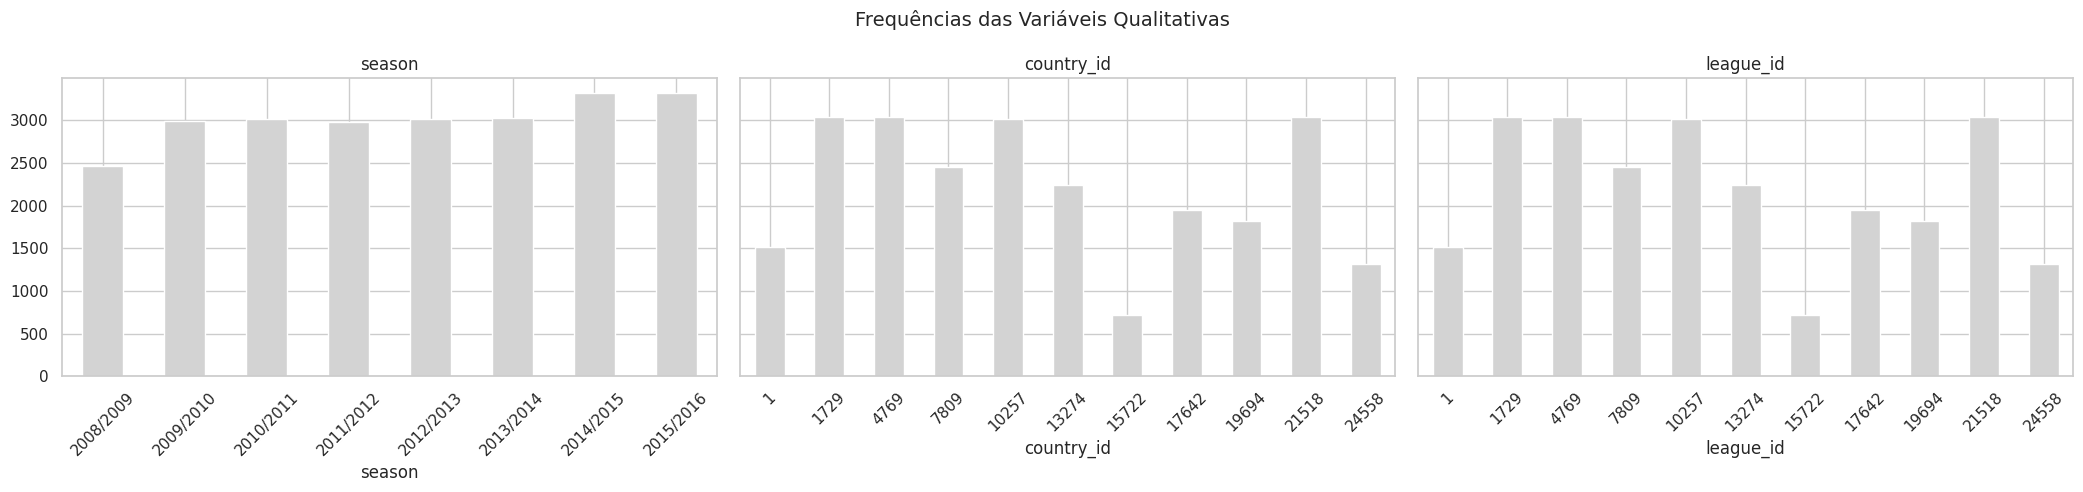

In [99]:
fig, axes = plt.subplots(1, len(VARS_QUALI), figsize=(7 * len(VARS_QUALI), 5), sharey=True)

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45) # Rotate labels for better readability

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

a variação está condizente e bem distrubida, principalmente com a analise pratica das nossas variaveis

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [100]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["home_team_outcome"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
season,8.0,1.35,0.998
country_id,11.0,4.22,0.972
league_id,11.0,4.22,0.972
home_team_outcome,2.0,1.18,0.995


parece desbalanceado mas as ligas tem aspectos macro, individuais que justificam e os paises e ligas estão diretamente relacionados

**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

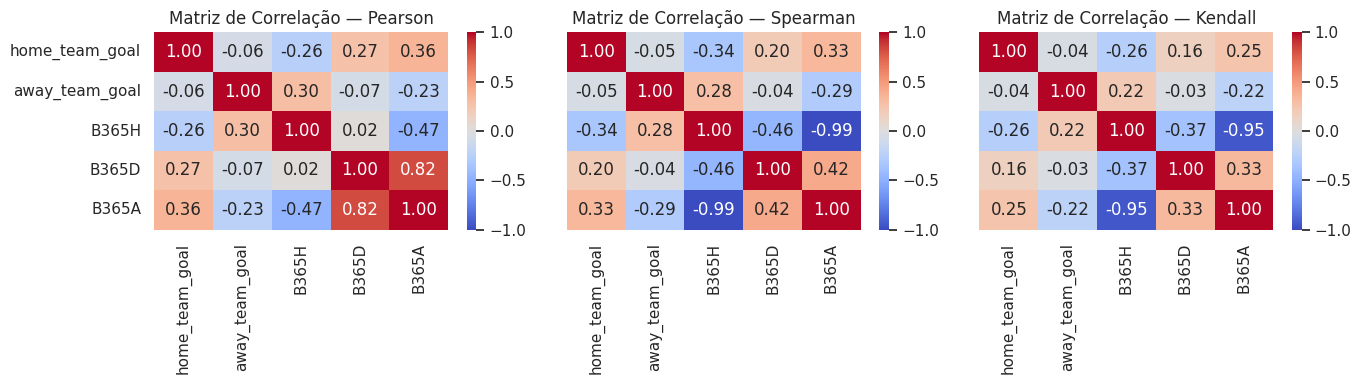

In [101]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Analisando as matrizes de correlação, podemos observar as relações entre as variáveis quantitativas (home_team_goal, away_team_goal, B365H, B365D, B365A) usando três métodos: Pearson, Spearman e Kendall. Embora Pearson meça a correlação linear, e Spearman e Kendall meçam a correlação monotônica (não necessariamente linear), os resultados são bastante consistentes entre si neste caso, o que sugere que as relações são predominantemente monotônicas. Destaca-se uma forte correlação negativa entre B365H (odds de vitória do time da casa) e B365A (odds de vitória do time visitante), com valores próximos a -0.99 para Spearman e Kendall, e -0.47 para Pearson. Isso é esperado, pois a chance de vitória de um time é inversamente proporcional à chance de vitória do outro. Também há correlações positivas moderadas entre B365D (odds de empate) e B365A, o que pode indicar que, em jogos onde o empate é mais provável, as odds para a vitória do time visitante também tendem a ser maiores. As correlações envolvendo home_team_goal e away_team_goal com as odds são mais fracas, mas apontam para a lógica de que mais gols em casa podem se correlacionar negativamente com as odds para a vitória em casa (pois a odd é menor para um time favorito que marca mais).

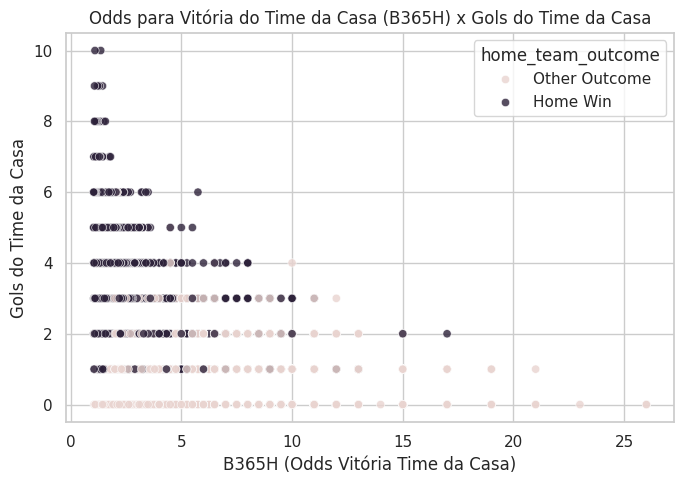

In [102]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="B365H", y="home_team_goal", hue="home_team_outcome",
                palette=palette_classe, alpha=0.8)
plt.title("Odds para Vitória do Time da Casa (B365H) x Gols do Time da Casa")
plt.xlabel("B365H (Odds Vitória Time da Casa)")
plt.ylabel("Gols do Time da Casa")
plt.tight_layout()
plt.show()

a relação de odd com vitoria é um para um, o numero de gols nao é um avaliador necessario, podendo ser tratado como outlier

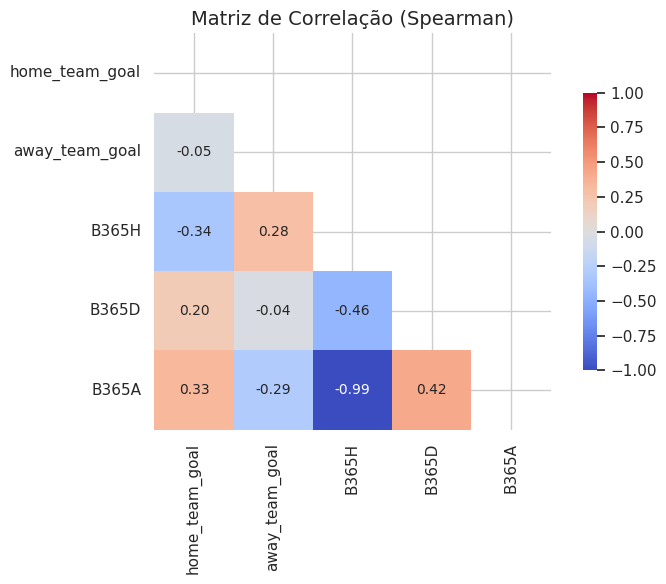

In [103]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(8, 6)) # Increased figure size
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,
            linewidths=0.0, linecolor='white', # Set linewidths to 0.0 to remove lines between cells
            cbar_kws={'shrink': 0.7}, # Adjust color bar size
            annot_kws={'fontsize': 10}) # Adjust annotation font size
plt.title("Matriz de Correlação (Spearman)", fontsize=14) # Add a title
# Removed plt.grid(False) as linewidths=0.0 handles this for the heatmap itself.

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

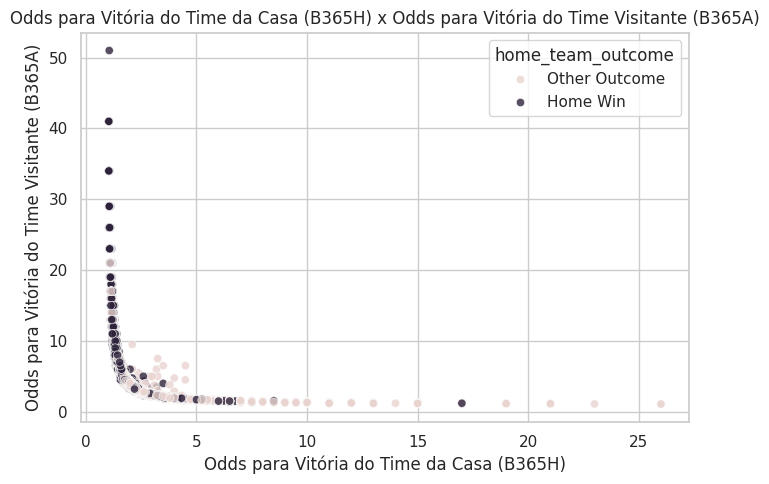

In [104]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="B365H", y="B365A", hue="home_team_outcome",
                palette=palette_classe, alpha=0.8)
plt.title("Odds para Vitória do Time da Casa (B365H) x Odds para Vitória do Time Visitante (B365A)")
plt.xlabel("Odds para Vitória do Time da Casa (B365H)")
plt.ylabel("Odds para Vitória do Time Visitante (B365A)")
plt.tight_layout()
plt.show()

pode-se concluir aqui que o time visitante costuma ganhar com odds muito mais altas que o time dacasa

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [105]:
resultados_comparacao = []
for col in VARS_QUANT:
    # Use 'home_team_outcome' and its classes for grouping
    grupo_other_outcome = df.loc[df["home_team_outcome"] == "Other Outcome", col]
    grupo_home_win = df.loc[df["home_team_outcome"] == "Home Win", col]

    # Ensure both groups have data before performing tests
    if not grupo_other_outcome.empty and not grupo_home_win.empty:
        # Welch's t-test (parametric, assumes unequal variances)
        stat_t, p_t = stats.ttest_ind(grupo_other_outcome, grupo_home_win, equal_var=False)
        # Mann-Whitney U test (non-parametric)
        stat_u, p_u = stats.mannwhitneyu(grupo_other_outcome, grupo_home_win)

        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": round(p_t, 5),
            "p_valor_mannwhitney": round(p_u, 5),
            "concordam": (p_t < 0.05) == (p_u < 0.05),
        })
    else:
        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": np.nan,
            "p_valor_mannwhitney": np.nan,
            "concordam": np.nan,
        })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
home_team_goal,0.0,0.0,True
away_team_goal,0.0,0.0,True
B365H,NaN,NaN,True
B365D,NaN,NaN,True
B365A,NaN,NaN,True


aquivemos tanto a dicotomia como a falta de relação dos gols(discuti sobre isso em sala com maira)

**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — home_team_goal entre categorias de league_id: estatística=18.548, p-valor=2.3607e-34
Kruskal-Wallis — home_team_goal entre categorias de league_id: estatística=156.057, p-valor=2.1088e-28


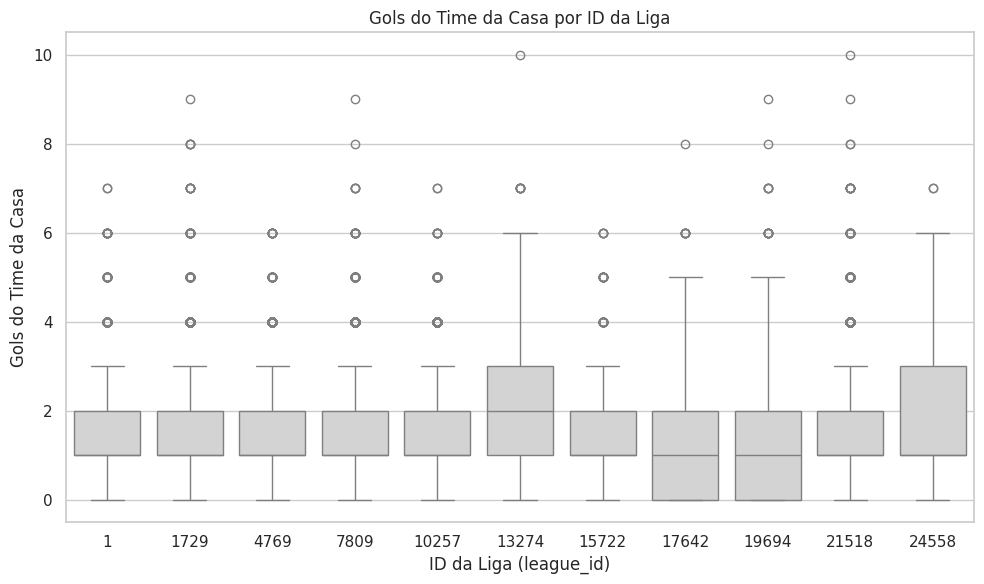

In [106]:
grupos_league_id = [grupo["home_team_goal"].dropna().values for _, grupo in df.groupby("league_id")]

# Ensure there are at least two groups with data for comparison
if len(grupos_league_id) >= 2:
    stat_anova, p_anova = stats.f_oneway(*grupos_league_id)   # paramétrico
    stat_kw, p_kw = stats.kruskal(*grupos_league_id)          # não-paramétrico

    print(f"ANOVA          — home_team_goal entre categorias de league_id: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
    print(f"Kruskal-Wallis — home_team_goal entre categorias de league_id: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")
else:
    print("Não há grupos suficientes para realizar os testes ANOVA/Kruskal-Wallis.")

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="league_id", y="home_team_goal", color=COR_NEUTRA)
plt.title("Gols do Time da Casa por ID da Liga")
plt.xlabel("ID da Liga (league_id)")
plt.ylabel("Gols do Time da Casa")
plt.tight_layout()
plt.show()

vemos aqui que algumas ligas  tem menos gols que outras mas em geral sao baixas, com destaque pras ligas francesas e alemaes que tem mais gols

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

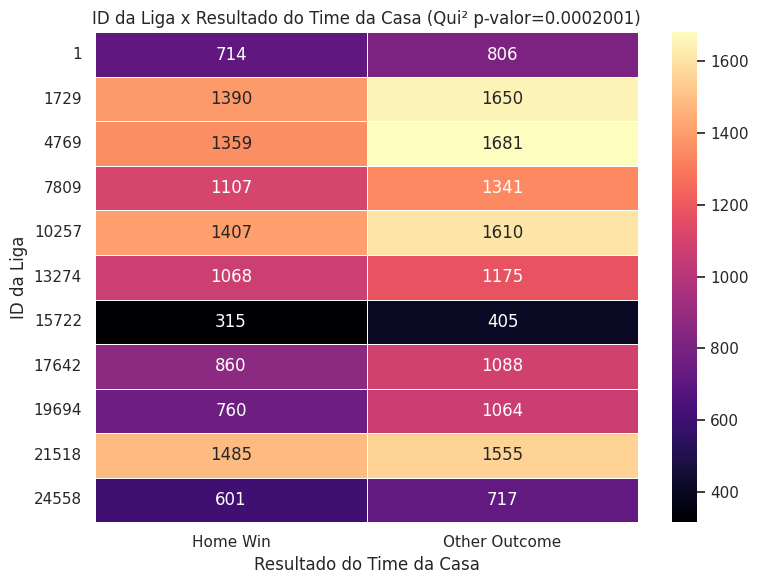

In [107]:
contingencia_league_outcome = pd.crosstab(df["league_id"], df["home_team_outcome"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_league_outcome)

fig, ax = plt.subplots(figsize=(8, 6)) # Increased figure size for better readability
sns.heatmap(contingencia_league_outcome, annot=True, fmt="d", cmap="magma", ax=ax, linewidths=.5, linecolor='white')
ax.set_title(f"ID da Liga x Resultado do Time da Casa (Qui² p-valor={p_chi2:.4g})")
plt.xlabel("Resultado do Time da Casa")
plt.ylabel("ID da Liga")
plt.tight_layout()
plt.show()

O mapa de calor da contingência entre ID da Liga e Resultado do Time da Casa revela uma associação estatisticamente significativa, conforme indicado pelo p-valor do teste Qui-Quadrado (0.0002). Observa-se que a proporção de 'Vitórias em Casa' versus 'Outros Resultados' varia entre as diferentes ligas, sugerindo que o desempenho dos times da casa pode ser influenciado pelo contexto da liga em que atuam.



**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

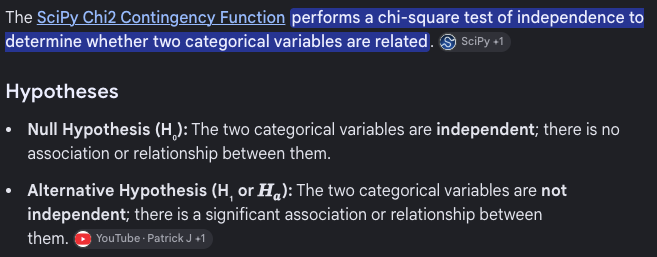

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [108]:
df["country_label"] = df["country_id"].astype(str)
# For 'league_id', we'll categorize it into bins or use it directly as a categorical variable
# Let's categorize league_id into bins, similar to age groups, for demonstration purposes.
# First, inspect the unique values or range of league_id to decide on bins.
# For now, let's just use it as a categorical label directly, similar to country_label, or create some simple bins.
# Given there are many unique league_ids, direct use is probably better or binning based on domain knowledge.
# For a generic adaptation, we can bin it. Let's create 3 bins for example.

# Get unique league IDs and sort them to create sensible bins
unique_leagues = sorted(df['league_id'].unique())
# Create simple bins based on the sorted unique league IDs
num_bins = 3 # You can adjust this number
league_bins = np.array_split(unique_leagues, num_bins)

def map_league_to_bin(league_id):
    for i, bin_list in enumerate(league_bins):
        if league_id in bin_list:
            return f"League_Bin_{i+1}"
    return "Other"

df["league_bin"] = df["league_id"].apply(map_league_to_bin)

print("Desbalanceamento — país:")
print(metrica_desbalanceamento(df["country_label"]))
print("\nDesbalanceamento — bin da liga:")
print(metrica_desbalanceamento(df["league_bin"]))

Desbalanceamento — país:
n_classes                 11.000
razao_desbalanceamento     4.220
entropia_normalizada       0.972
dtype: float64

Desbalanceamento — bin da liga:
n_classes                 3.000
razao_desbalanceamento    1.630
entropia_normalizada      0.982
dtype: float64


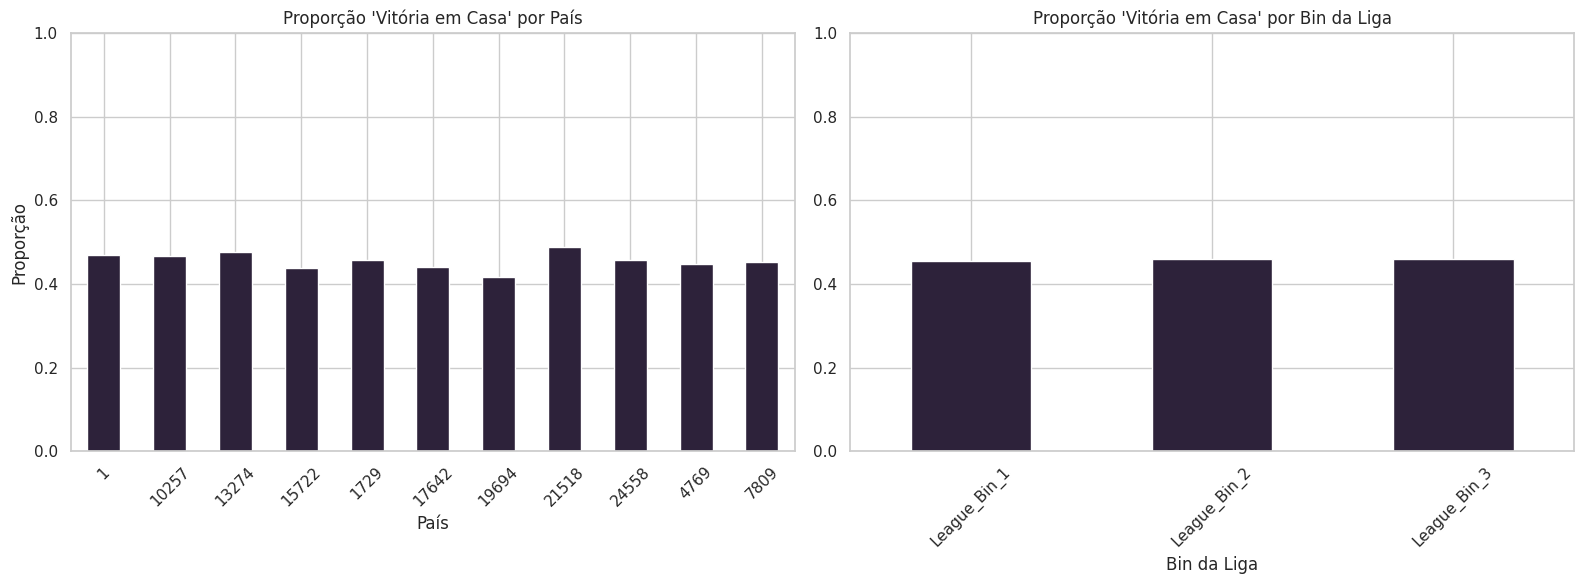

In [109]:
prop_por_country = pd.crosstab(df["country_label"], df["home_team_outcome"], normalize="index").round(3)
prop_por_league_bin = pd.crosstab(df["league_bin"], df["home_team_outcome"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # Increased figure size

prop_por_country["Home Win"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Vitória em Casa' por País")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45) # Rotate labels for better readability
axes[0].set_xlabel("País")

prop_por_league_bin["Home Win"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Vitória em Casa' por Bin da Liga")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_xlabel("Bin da Liga")

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

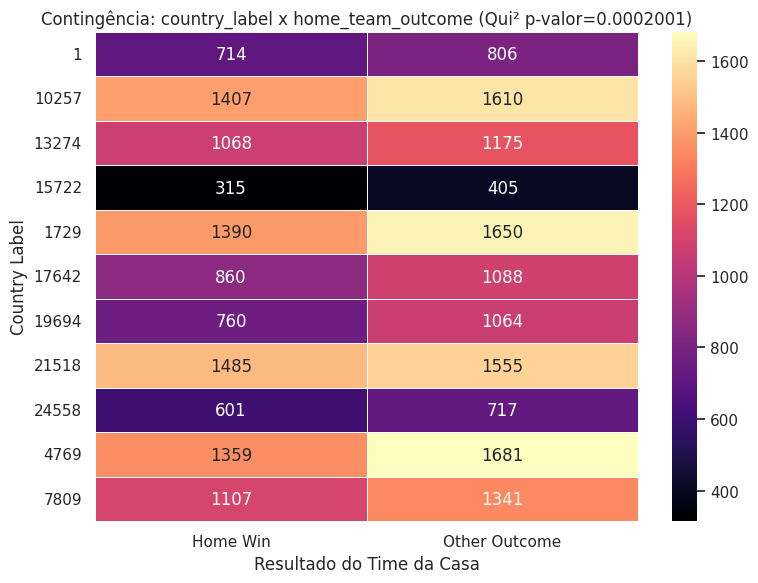

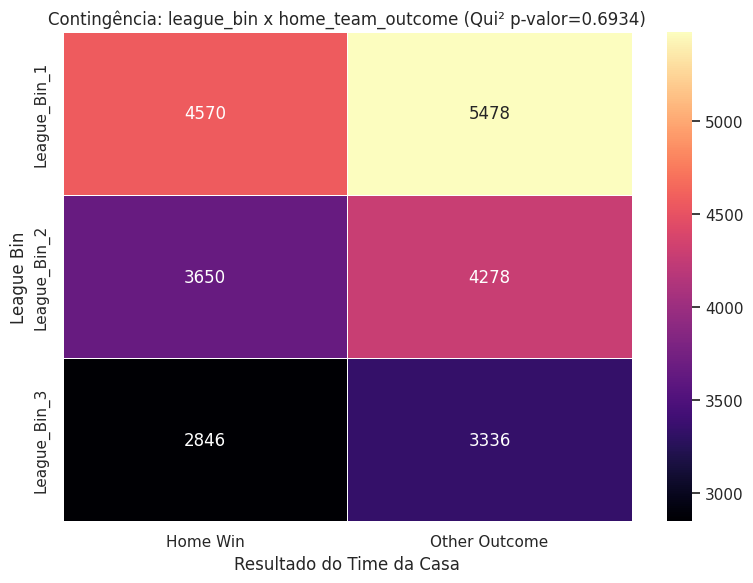

In [111]:
for atributo in ["country_label", "league_bin"]:
    contingencia = pd.crosstab(df[atributo], df["home_team_outcome"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax, linewidths=.5, linecolor='white')
    ax.set_title(f"Contingência: {atributo} x home_team_outcome (Qui² p-valor={p_valor:.4g})")
    plt.xlabel("Resultado do Time da Casa")
    plt.ylabel(atributo.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()

Com base na análise das tabelas de contingência e mapas de calor, observamos que:

País (country_label) vs. Resultado do Time da Casa (home_team_outcome): Há uma associação estatisticamente significativa entre o país e o resultado da partida em casa (vitória do time da casa ou outro resultado), com um p-valor do teste Qui-Quadrado de 0.0002. Isso sugere que a proporção de vitórias em casa varia entre os diferentes países.

Agrupamento da Liga (league_bin) vs. Resultado do Time da Casa (home_team_outcome): Não foi encontrada uma associação estatisticamente significativa entre o agrupamento da liga e o resultado da partida em casa, com um p-valor do teste Qui-Quadrado de 0.6934. Isso indica que a proporção de vitórias em casa é semelhante entre os diferentes grupos de ligas binários que criamos.

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

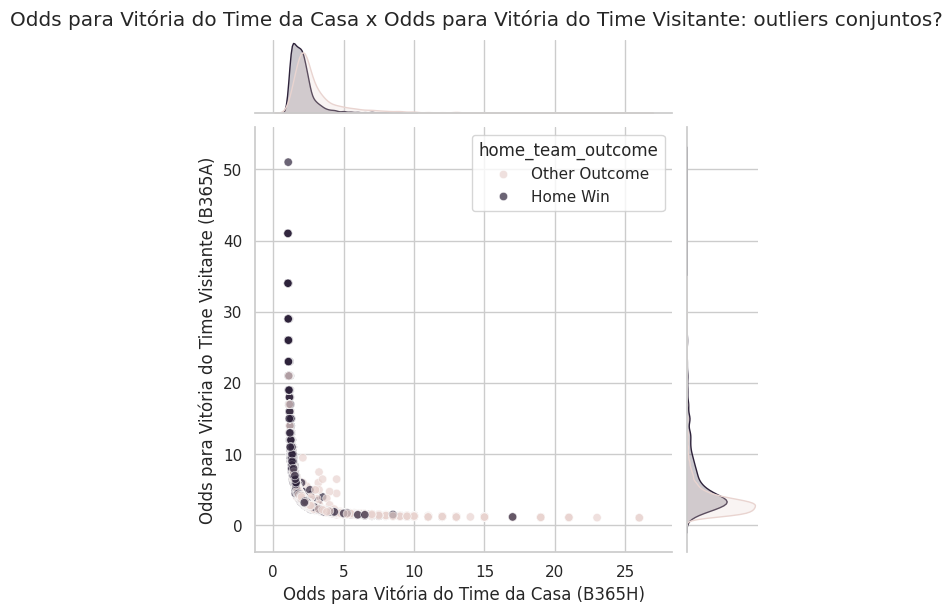

In [112]:
sns.jointplot(data=df, x="B365H", y="B365A", hue="home_team_outcome",
              palette=palette_classe, alpha=0.7, height=6)
plt.suptitle("Odds para Vitória do Time da Casa x Odds para Vitória do Time Visitante: outliers conjuntos?", y=1.02)
plt.xlabel("Odds para Vitória do Time da Casa (B365H)")
plt.ylabel("Odds para Vitória do Time Visitante (B365A)")
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

#### Análise Multivariada

##### Matriz de Correlação

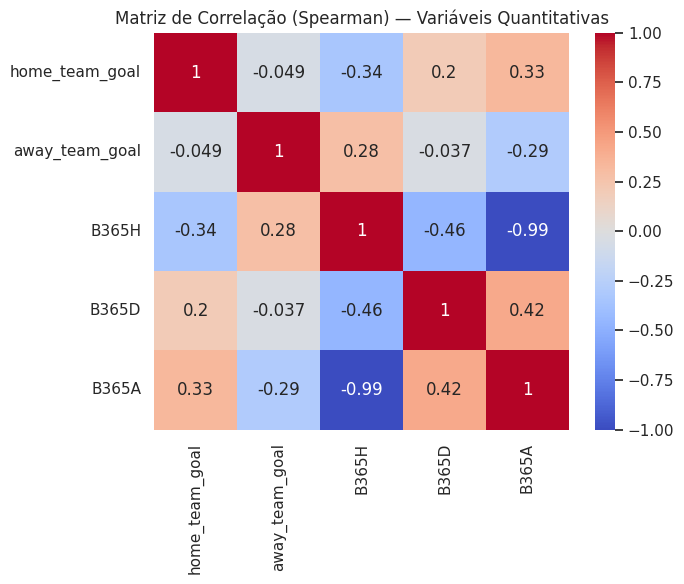

In [113]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

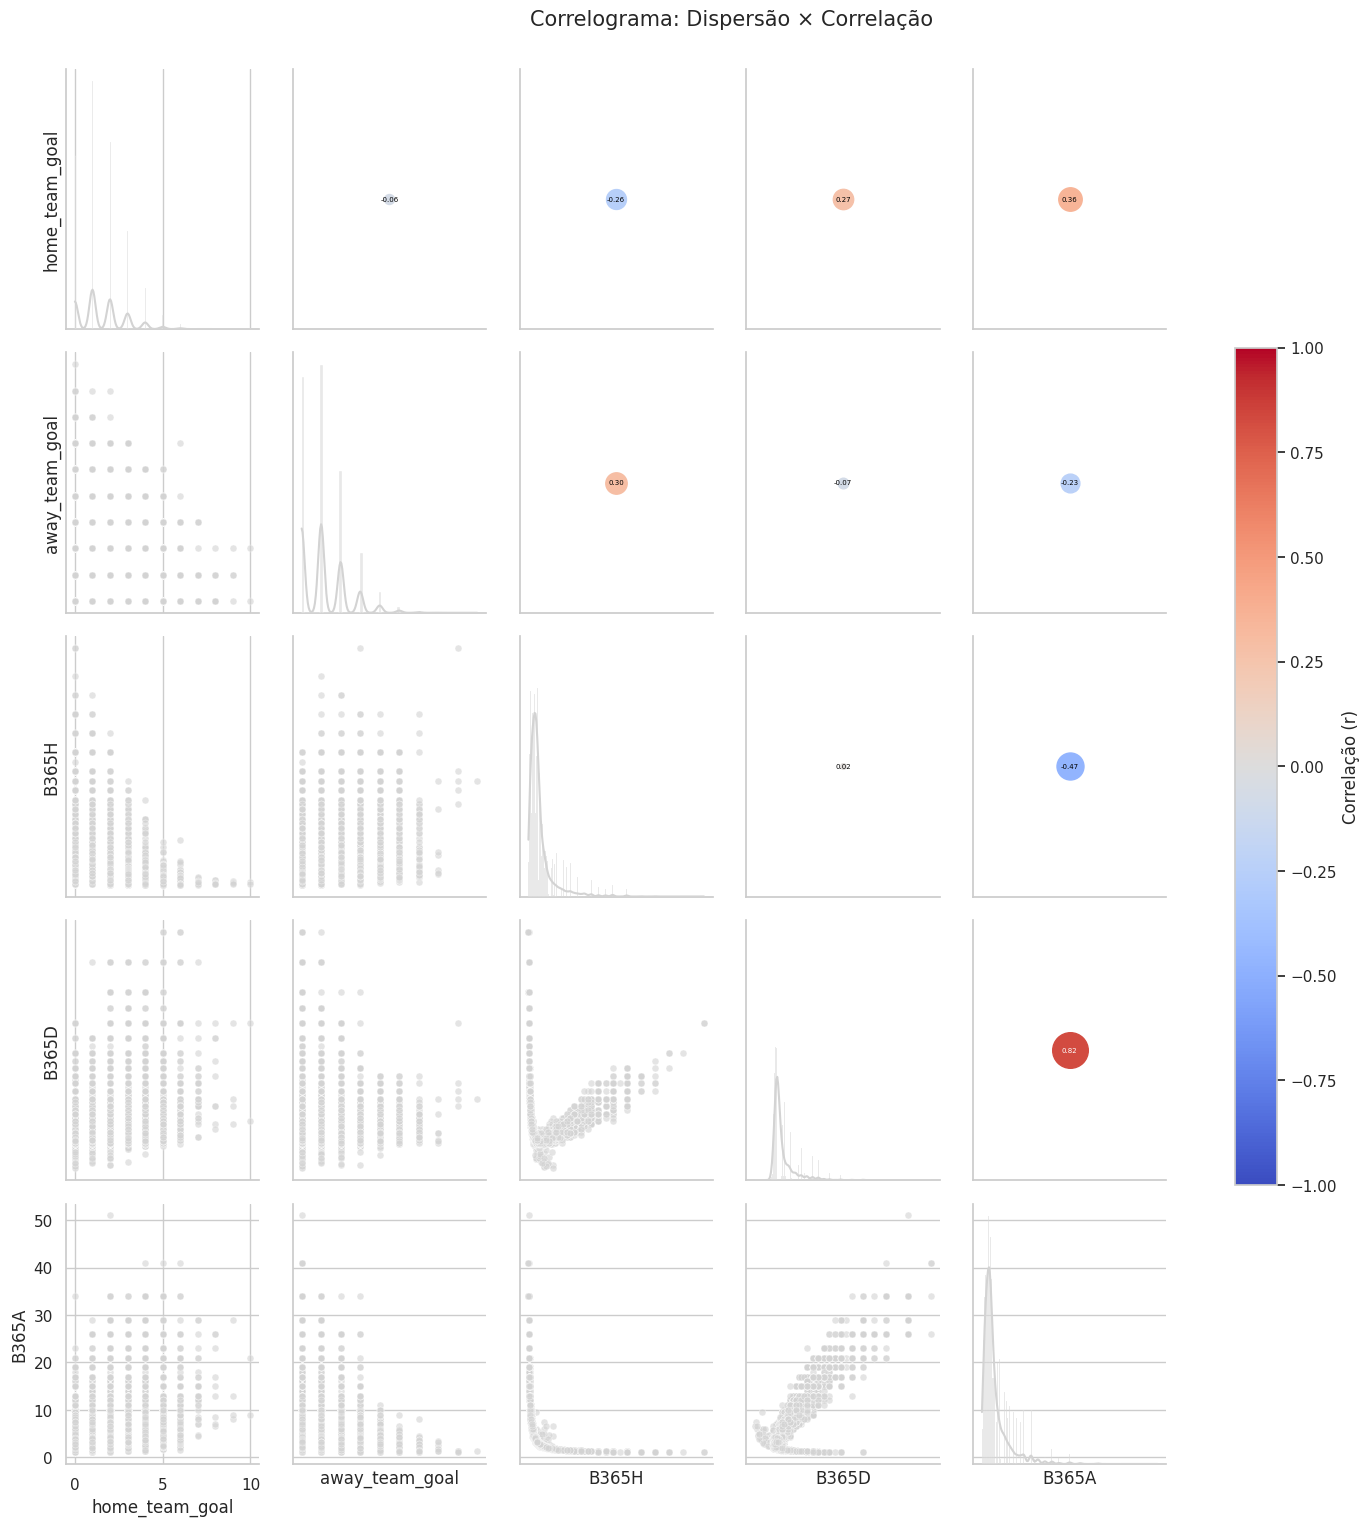

In [114]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import pandas as pd

def circulo_correlacao(x, y, **kwargs):
    ax = plt.gca()

    # Create a temporary DataFrame to align x and y and drop NaNs together
    temp_df = pd.DataFrame({'x': x, 'y': y}).dropna()

    if len(temp_df) >= 2: # Need at least two non-NaN pairs to calculate correlation
        r = temp_df['x'].corr(temp_df['y']) # Use pandas .corr() for robust pairwise correlation

        if not np.isnan(r):
            ax.scatter(
                [0.5], [0.5],
                s=abs(r) * 800,          # Further reducing size for less overlap
                c=[r], cmap='coolwarm', vmin=-1, vmax=1,
                transform=ax.transAxes
            )
            ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                        ha="center", va="center", fontsize=5, # Further reducing font size
                        color="white" if abs(r) > 0.5 else "black")
        else:
            ax.annotate("N/A", xy=(0.5, 0.5), xycoords=ax.transAxes,
                        ha="center", va="center", fontsize=5, color="gray")
    else:
        ax.annotate("N/A", xy=(0.5, 0.5), xycoords=ax.transAxes,
                    ha="center", va="center", fontsize=5, color="gray")

    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False, height=3) # Aumentando o tamanho de cada subplot
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
plt.show()

podemos concluir que mesmo que tudo tenha uma alta variabilidade, em geral,tem estabilidade e compreemsivibilidade ALTISSIMA, e aliado a isso pode-se afirmar que DIFERENTE DE TODO ESSE PADRÃO, as odds e bets nao julgam só resultados estatisticos como o que os times fazem e a relevancia, bagunçando a logica e causando altos valores e valores descontrolados principalmente se tratando de vitorias derrotas e empates, assim podemos afirmar que não devemos apostar em hipotese alguma mas PRINCIPLAMENTE nas famigeradas ODDS altas que nem sempre conversam com a realidade dos jogos que sãio geralmente precisos d=e de valores mais concentrados nos numeros de baiaxs unidades, improbabilizando as odds altas de darem algum fruto financeiro e esportivo condizente.

## 7. Exportação do Dataset Tratado

Conforme a especificação do projeto, exportamos o dataset limpo e tratado para `data/clean/dataset.csv` para consumo pelo aplicativo Streamlit.

In [ ]:
import os
os.makedirs('../data/clean', exist_ok=True)
df.to_csv('../data/clean/dataset.csv', index=False)
print(f'Dataset limpo exportado com sucesso para ../data/clean/dataset.csv! Shape: {df.shape}')